In [1]:
pip install torch torchvision numpy pandas matplotlib scikit-learn datasets pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import pandas as pd
import da

C:\Users\jai19\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Load MNIST (source) and MNIST-M (target), 3-channel 32x32, 10k-image training subsample per domain
da.set_seed(0)
data = da.load_data()
for k, (x, y) in data.items():
    print(k, tuple(x.shape))

mnist_train (10000, 3, 32, 32)
mnist_test (10000, 3, 32, 32)
mnistm_train (10000, 3, 32, 32)
mnistm_test (9001, 3, 32, 32)


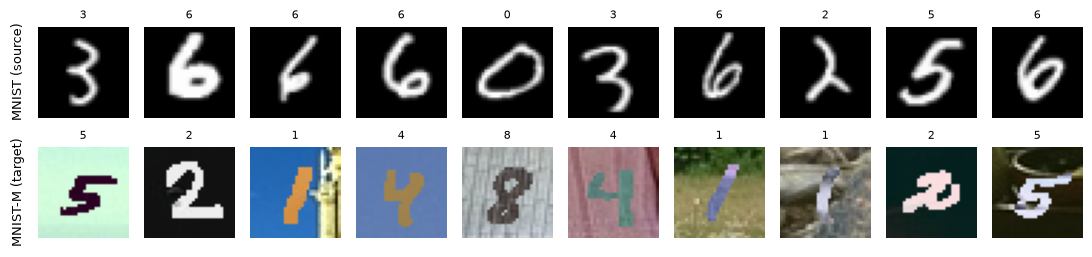

In [4]:
# Sample images from both domains
da.sample_grid(data, "figures/samples.png")

In [5]:
# Source-only, AdaBN, DANN and target-only on 3 seeds, 20 epochs each
logs = []
def log(s):
    logs.append(s)
    print(s)
res, models = da.run_all(data, seeds=(0, 1, 2), epochs=20, log=log)
res["logs"] = logs

[source_only] seed 0 epoch 1/20 loss 0.4361


[source_only] seed 0 epoch 2/20 loss 0.0674


[source_only] seed 0 epoch 3/20 loss 0.0467


[source_only] seed 0 epoch 4/20 loss 0.0328


[source_only] seed 0 epoch 5/20 loss 0.0199


[source_only] seed 0 epoch 6/20 loss 0.0173


... (182 outputs left out)

seed 2 source_only: MNIST 98.95  MNIST-M 14.98


seed 2 adabn: MNIST 56.85  MNIST-M 41.56


seed 2 dann: MNIST 96.43  MNIST-M 17.95


seed 2 target_only: MNIST 87.91  MNIST-M 95.10


In [6]:
# Results table
names = {"source_only": "Source-only", "adabn": "AdaBN", "dann": "DANN", "target_only": "Target-only"}
rows = [{"Method": names[k], "MNIST acc (%)": f"{v['mnist_mean']:.2f} +/- {v['mnist_std']:.2f}",
         "MNIST-M acc (%)": f"{v['mnistm_mean']:.2f} +/- {v['mnistm_std']:.2f}",
         "% gap closed": f"{v['gap_mean']:.1f} +/- {v['gap_std']:.1f}"} for k, v in res["summary"].items()]
pd.DataFrame(rows)

,Method,MNIST acc (%),MNIST-M acc (%),% gap closed
0,Source-only,98.93 +/- 0.03,16.54 +/- 1.49,0.0 +/- 0.0
1,AdaBN,61.30 +/- 11.47,42.68 +/- 2.83,33.3 +/- 2.7
2,DANN,96.17 +/- 1.74,26.33 +/- 8.07,12.5 +/- 10.2
3,Target-only,91.16 +/- 2.40,95.03 +/- 0.08,100.0 +/- 0.0


In [7]:
# Save every number the report uses
with open("results.json", "w") as f:
    json.dump(res, f, indent=2)

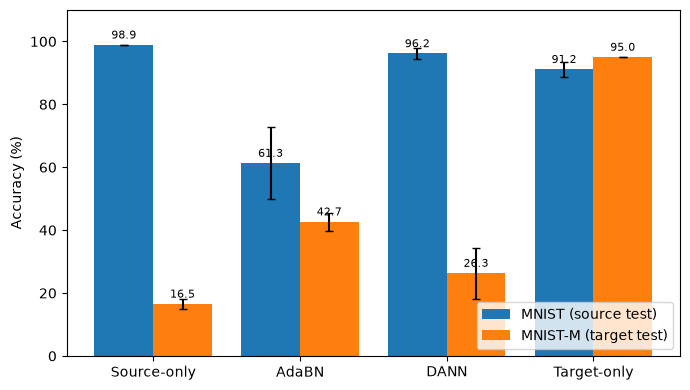

In [8]:
# Bar chart of the results table
da.bar_chart(res["summary"], "figures/results_bar.png")

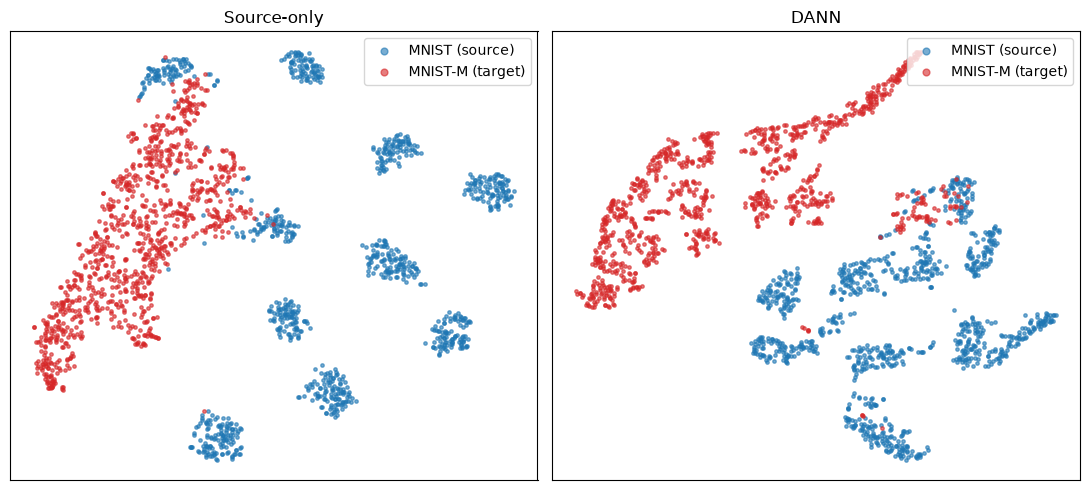

In [9]:
# t-SNE of penultimate features, source-only vs DANN (seed 0 models)
da.tsne_plot({"Source-only": models["source_only"], "DANN": models["dann"]}, data, "figures/tsne.png")

In [10]:
# Render the seed-0 training logs as images
s0 = [l for l in logs if "seed 0" in l]
da.log_image([l for l in s0 if l.startswith("[source_only]")] + [l for l in s0 if l.startswith("[target_only]")], "figures/log_supervised.png", "Source-only and target-only training (seed 0)")
da.log_image([l for l in s0 if l.startswith("[dann]")], "figures/log_dann.png", "DANN training (seed 0)")
da.log_image([l for l in logs if l.startswith("seed ")], "figures/log_eval.png", "Test accuracy per seed")